In [1]:
%%! 
export ASAN_OPTIONS=detect_leaks=0

[]

In [2]:
import ksets_cpp as cksets
from importlib import reload
import pathlib
import numpy as np
import ksets_cpp.uef_clustering.ksets as ksets
np.__version__
cksets = reload(cksets)
ksets = reload(ksets)

In [3]:
datadir = pathlib.Path("..") / "data" / "artificial"

In [4]:
list(datadir.glob("*1200_100_16_5_1*"))

[PosixPath('../data/artificial/data_1200_100_16_5_1.txt'),
 PosixPath('../data/artificial/representative_1200_100_16_5_1.txt'),
 PosixPath('../data/artificial/gt_labels_1200_100_16_5_1.txt')]

In [5]:
data_f, rep, gt_labels = list(datadir.glob("*1200_100_16_5_1*"))

In [6]:
manual_entry = False
if manual_entry:
    data = [
        ["A", "E", "B", "C", "F"],
        ["D", "G", "A", "B"],
        ["I", "A", "C", "J", "B"],
        ["A", "H", "C", "B"],
        ["A", "E", "F", "C", "B"],
        ["D", "G", "A", "B"]]
    data = np.array([np.array(x) for x in data], dtype="object")
else:
    data = cksets.read_file(data_f)

data

array([array(['L94', 'K31', 'H32', 'H48', 'C02', 'D59'], dtype='<U3'),
       array(['J45', 'B27', 'Q16', 'M51', 'S60'], dtype='<U3'),
       array(['A02', 'S89', 'G57', 'F92', 'R92', 'H48'], dtype='<U3'),
       ...,
       array(['F44', 'A02', 'B18', 'I79', 'B27', 'S20'], dtype='<U3'),
       array(['F92', 'M93', 'Q16', 'G57', 'T27', 'H50', 'N12', 'F22', 'C15',
              'H32', 'L43'], dtype='<U3')                                   ,
       array(['G37', 'J45', 'A02', 'H32'], dtype='<U3')],
      shape=(1200,), dtype=object)

In [7]:
import timeit
K = 128 # Number of clusters
MAX_HIST_LENGTH = 0 #20 # if zero no limitation
RS_ITER = 300 # number of iterations for kswaps
#rand_seed =None
rand_seed = 33
np.random.seed(rand_seed)
initial_hist = cksets.build_initial_histograms(data, K)
initial_hist

[{np.str_('A70'): np.int64(1),
  np.str_('H32'): np.int64(1),
  np.str_('J45'): np.int64(1),
  np.str_('N30'): np.int64(1),
  np.str_('O28'): np.int64(1),
  np.str_('Q98'): np.int64(1)},
 {np.str_('F92'): np.int64(1),
  np.str_('G37'): np.int64(1),
  np.str_('G57'): np.int64(1),
  np.str_('H50'): np.int64(1),
  np.str_('M93'): np.int64(1),
  np.str_('N94'): np.int64(1),
  np.str_('Q98'): np.int64(1),
  np.str_('T27'): np.int64(1)},
 {np.str_('B18'): np.int64(1),
  np.str_('B43'): np.int64(1),
  np.str_('C02'): np.int64(1),
  np.str_('F22'): np.int64(1),
  np.str_('G21'): np.int64(1),
  np.str_('H26'): np.int64(1),
  np.str_('I45'): np.int64(1),
  np.str_('L71'): np.int64(1),
  np.str_('M93'): np.int64(1),
  np.str_('N28'): np.int64(1),
  np.str_('Q80'): np.int64(1),
  np.str_('Q98'): np.int64(1),
  np.str_('R05'): np.int64(1),
  np.str_('R23'): np.int64(1),
  np.str_('R54'): np.int64(1),
  np.str_('S80'): np.int64(1),
  np.str_('T20'): np.int64(1),
  np.str_('V49'): np.int64(1)},
 {np.

In [8]:
from memory_profiler import memory_usage
import pandas as pd

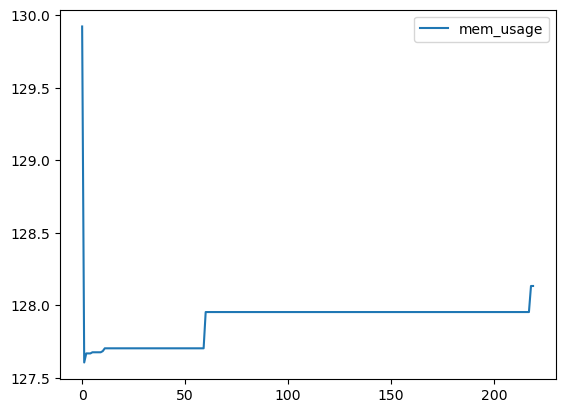

In [9]:
mem_usage = pd.DataFrame({"mem_usage": memory_usage((cksets.cluster,(data, K, MAX_HIST_LENGTH, None, 50), {"hist_rebuild":"full"}), interval=0.001)})
ax2 = mem_usage.plot()
ax2.ticklabel_format(useOffset=False)

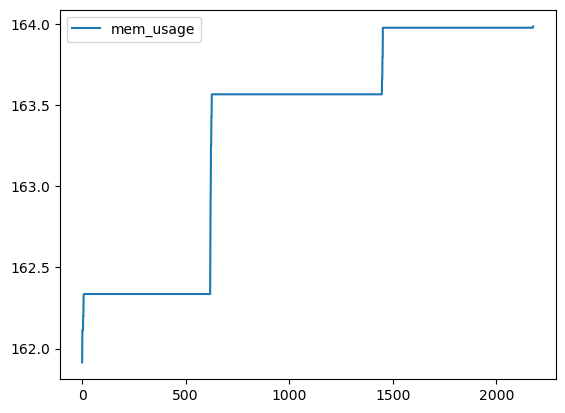

In [10]:

mem_usage = pd.DataFrame({"mem_usage": memory_usage((ksets.cluster,(data, K, MAX_HIST_LENGTH, None, 50)), interval=0.001)})
ax = mem_usage.plot()
ax.ticklabel_format(useOffset=False)

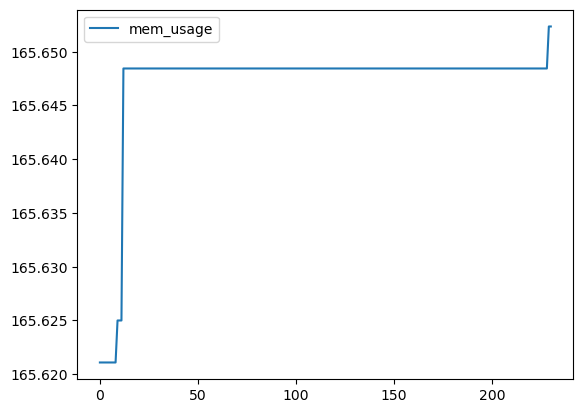

In [11]:
mem_usage = pd.DataFrame({"mem_usage": memory_usage((cksets.cluster,(data, K, MAX_HIST_LENGTH, None, 50), {"hist_rebuild":"memorize"}), interval=0.001)})
ax3 = mem_usage.plot()
ax3.ticklabel_format(useOffset=False)

In [12]:
ksets.LOG_ENABLE = False
ksets.LOG_ITERCOUNT = 1
print(timeit.timeit('labels, khist, sdh = cksets.cluster(data, K, MAX_HIST_LENGTH, None, 50, hist_rebuild="full")', number=10 ,globals=globals()))

2.5038377908058465


In [22]:
print(timeit.timeit('labels, khist, sdh = cksets.cluster(data, K, MAX_HIST_LENGTH, None, 50, hist_rebuild="full", preselect="ibf")', number=10,globals=globals()))

2.4823982999660075


In [14]:
#print(timeit.timeit('labels, khist, sdh = ksets.cluster(data, K, MAX_HIST_LENGTH, None, 50)', number=1,globals=globals()))

In [15]:
clabels, ckhist, csdh = cksets.cluster(data, K, MAX_HIST_LENGTH, initial_hist,50,hist_rebuild="full", preselect="ibf")

In [16]:
labels, khist, sdh = ksets.cluster(data, K, MAX_HIST_LENGTH, initial_hist, 50)

In [17]:

list(f"{x},{y}" for x,y in zip(clabels,labels) if x!=y)

['24,78',
 '118,34',
 '124,65',
 '0,46',
 '120,9',
 '0,98',
 '44,122',
 '126,26',
 '11,60',
 '98,127',
 '28,100',
 '80,24',
 '98,127',
 '126,26',
 '120,9',
 '102,66',
 '28,100',
 '118,34',
 '114,113',
 '0,46',
 '114,54',
 '86,5',
 '44,122',
 '102,66',
 '126,26',
 '0,46',
 '44,122',
 '86,57',
 '28,100',
 '126,26',
 '32,26',
 '13,24',
 '114,54',
 '118,34',
 '11,60',
 '0,46',
 '13,24',
 '80,24',
 '43,39',
 '86,5',
 '28,100',
 '69,66',
 '86,5',
 '114,54',
 '86,5',
 '102,66',
 '114,54',
 '0,46',
 '80,24',
 '114,54',
 '1,59',
 '86,5',
 '102,66',
 '80,24',
 '114,54',
 '28,100',
 '126,26',
 '114,54',
 '11,60',
 '118,34',
 '102,66',
 '118,34',
 '11,60',
 '1,59',
 '86,5',
 '114,54',
 '120,9',
 '11,60',
 '73,65',
 '0,46',
 '11,60',
 '28,27',
 '86,5',
 '118,34',
 '24,78',
 '1,59',
 '1,59',
 '28,100',
 '114,54',
 '28,100',
 '114,54',
 '1,59',
 '80,24',
 '86,5',
 '13,24',
 '39,46',
 '86,5',
 '102,66',
 '28,100',
 '13,24',
 '24,78',
 '86,5',
 '1,59',
 '1,59',
 '120,9',
 '80,24',
 '63,60',
 '126,26',


In [18]:
khist

[{np.str_('A70'): np.int64(1),
  np.str_('D15'): np.int64(1),
  np.str_('G37'): np.int64(1),
  np.str_('H32'): np.int64(2),
  np.str_('J45'): np.int64(2),
  np.str_('N30'): np.int64(1),
  np.str_('O28'): np.int64(2),
  np.str_('Q16'): np.int64(1),
  np.str_('Q98'): np.int64(2)},
 {np.str_('F92'): np.int64(1),
  np.str_('G37'): np.int64(1),
  np.str_('G57'): np.int64(1),
  np.str_('H50'): np.int64(1),
  np.str_('M93'): np.int64(1),
  np.str_('N94'): np.int64(1),
  np.str_('Q98'): np.int64(1),
  np.str_('T27'): np.int64(1)},
 {np.str_('B18'): np.int64(2),
  np.str_('B43'): np.int64(4),
  np.str_('C02'): np.int64(2),
  np.str_('C85'): np.int64(1),
  np.str_('D22'): np.int64(1),
  np.str_('D37'): np.int64(1),
  np.str_('D59'): np.int64(1),
  np.str_('E44'): np.int64(1),
  np.str_('F09'): np.int64(2),
  np.str_('F22'): np.int64(1),
  np.str_('F78'): np.int64(1),
  np.str_('G21'): np.int64(1),
  np.str_('G57'): np.int64(1),
  np.str_('G72'): np.int64(1),
  np.str_('H26'): np.int64(1),
  np.s

In [19]:
list(f"{x},{y}" for x,y in zip(sdh,csdh) if x!=y)

[]

In [20]:
clabels

[39,
 24,
 118,
 34,
 122,
 34,
 66,
 24,
 120,
 66,
 101,
 24,
 121,
 24,
 0,
 66,
 124,
 122,
 122,
 96,
 34,
 66,
 122,
 46,
 101,
 0,
 26,
 120,
 122,
 120,
 122,
 28,
 92,
 0,
 44,
 2,
 118,
 39,
 126,
 11,
 98,
 28,
 39,
 80,
 122,
 101,
 98,
 61,
 126,
 101,
 120,
 24,
 102,
 28,
 34,
 98,
 118,
 39,
 114,
 0,
 114,
 86,
 39,
 3,
 44,
 102,
 33,
 126,
 0,
 44,
 120,
 2,
 86,
 26,
 80,
 120,
 28,
 126,
 24,
 34,
 57,
 32,
 13,
 66,
 114,
 29,
 120,
 120,
 118,
 65,
 11,
 94,
 46,
 0,
 65,
 121,
 52,
 39,
 13,
 66,
 86,
 34,
 122,
 86,
 3,
 39,
 101,
 80,
 43,
 65,
 86,
 26,
 120,
 121,
 122,
 122,
 83,
 28,
 101,
 122,
 12,
 69,
 122,
 101,
 86,
 65,
 114,
 11,
 98,
 63,
 116,
 33,
 86,
 82,
 26,
 80,
 46,
 122,
 1,
 1,
 46,
 101,
 102,
 39,
 19,
 122,
 85,
 34,
 80,
 26,
 114,
 0,
 39,
 98,
 34,
 24,
 80,
 65,
 114,
 43,
 26,
 85,
 54,
 91,
 1,
 86,
 69,
 120,
 102,
 16,
 80,
 24,
 65,
 120,
 114,
 26,
 54,
 28,
 126,
 114,
 11,
 101,
 77,
 101,
 16,
 118,
 34,
 65,
 39,
 34,
 7